# Notebook to build the script of Circonscription Map generation

## Retrieve Map from INSEE

In [1]:
import requests, geopandas as gpd

url = "https://www.data.gouv.fr/api/1/datasets/r/dbf42fce-a563-412e-9db1-1f7ab453c2ef"
r = requests.get(url)
#read zip file content into a GeoDataFrame
gpf_insee = gpd.read_file(r.content)
#return 5 first rows of the GeoDataFrame
gpf_insee.head(5)

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-61.03945 14.64265, -61.0394 14.6425..."


In [2]:
#test the Coordinate Reference System (CRS) of the GeoDataFrame
gpf_insee.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

### Simplify Map drawing to reduce Map size

1. convert CRS from EPSG:4326 to EPSG:3857 (meter based CRS)

In [5]:
gpf_insee_3857 = gpf_insee.to_crs(epsg=3857)
gpf_insee_3857.head(5)

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-6078306.99 259842.11, -607831..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-5781589.848 497711.173, -5781..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-6791039.757 1640603.641, -679..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-6804837.228 1646781.86, -6804..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-6794879.991 1648050.814, -6794874.6..."


In [29]:
types = []
for i in range(len(gpf_insee_3857)):
    types.append(type(gpf_insee_3857.geometry.iloc[i]))
    if not gpf_insee_3857.geometry.iloc[i].notna():
        print(f"Empty geometry at index {i}")
print(set(types))

AttributeError: 'MultiPolygon' object has no attribute 'notna'

In [17]:
type(NaN)

NameError: name 'NaN' is not defined

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

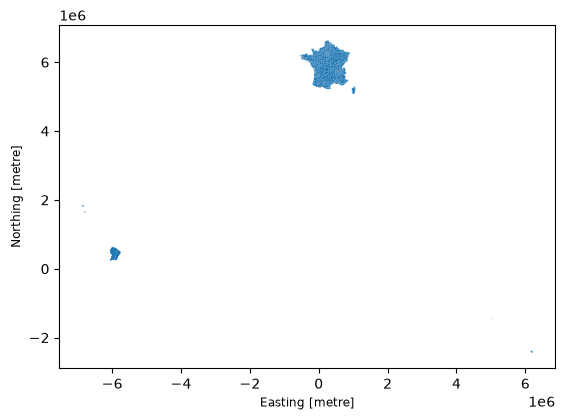

In [7]:
gpf_insee_3857.plot()

2. In the case of adjacent polygons we use simplify_coverage : warning geometry might need cleaning
```
from shapely import make_valid

# 1. Drop missing/empty and keep only Polygon / MultiPolygon
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
gdf = gdf[gdf.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

# 2. Repair invalid geometries and remove zero-area artifacts
gdf["geometry"] = gdf.geometry.apply(make_valid)
gdf = gdf[~gdf.geometry.is_empty & (gdf.geometry.area > 0)].copy()

# 3. Simplify coverage with a conservative tolerance first
simplified = gdf.geometry.simplify_coverage(tolerance=0.001)
```

### Tests few cases at circonscription border

## Retrieve COM (Communes D'Outre Mer) from ArcGIS Science PO service

### Download map of COM from Science PO service and change CRS (Coordinate Reference System)

## Concat Maps

## Export File to designated folder